In [5]:
from helpers import *
import numpy as np 
import matplotlib.pyplot as plt
import pickle
from scipy.stats import ks_2samp, wasserstein_distance
import os

In [6]:
for plot_type in ['spatial_cor', 'pv_cor', 'cross_cor', 'single_cell']:
    os.makedirs(f'plots/{plot_type}', exist_ok=True)

outputs = {}
for condition in ['exp', 'cont']:
    act_maps, burst_props = {}, {}
    for out in ['F1', 'F2', 'N1', 'F3', 'N2']:
        with open(f'simulation_data/2d/{condition}_{out}_inhplast_1.pkl', 'rb') as f:
            act_map = pickle.load(f)
        act_maps[out] = act_map

    outputs[condition] = act_maps

act_maps_exp = outputs['exp']
act_maps_cont = outputs['cont']

fig, axes = plt.subplots(3, 4, figsize=(16, 12), dpi=600)

act_maps_exp, act_maps_cont = smooth_act_maps([act_maps_exp, act_maps_cont], sigma=1)

correls_exp, correls_cont = [], []

for i, (out1, out2) in enumerate([('F1', 'F2'), ('F2', 'N1'), ('N1', 'N2')]):
    correlogram_exp = compute_cross_correlogram(act_maps_exp, out1, out2)
    smoothed_exp = gaussian_filter(correlogram_exp, sigma=1.5)

    correlogram_cont = compute_cross_correlogram(act_maps_cont, out1, out2)
    smoothed_cont = gaussian_filter(correlogram_cont, sigma=1.5)

    correls_exp.append(smoothed_exp)
    correls_cont.append(smoothed_cont)


all_ps = []
results = {}

for i, (out1, out2) in enumerate([('F1', 'F2'), ('F2', 'N1'), ('N1', 'N2')]):
    axs = axes[i, :]

    sp_exp = cor_act_maps_2d(act_maps_exp[out1], act_maps_exp[out2], which='spatial')
    sp_cont = cor_act_maps_2d(act_maps_cont[out1], act_maps_cont[out2], which='spatial')

    stat_sp, p_sp = ks_2samp(sp_exp, sp_cont)
    was_d_sp = wasserstein_distance(sp_exp, sp_cont)
    all_ps.append(p_sp)


    pv_exp = cor_act_maps_2d(act_maps_exp[out1], act_maps_exp[out2], which='pv')
    pv_cont = cor_act_maps_2d(act_maps_cont[out1], act_maps_cont[out2], which='pv')
    
    stat_pv, p_pv = ks_2samp(pv_exp, pv_cont)

    was_d_pv = wasserstein_distance(pv_exp, pv_cont)
    all_ps.append(p_pv)

    vmin = min(np.min(correls_exp[i]), np.min(correls_cont[i]))
    vmax = max(np.max(correls_exp[i]), np.max(correls_cont[i]))

    # --- Experimental map ---
    axs[0].set_ylabel('experimental', fontsize=20)
    plot_cross_correlogram(correls_exp[i], axs[0], title=None, cmap='jet', ylabel=None, vmin=vmin, vmax=vmax)

    # also save as standalone
    fig_single, ax_single = plt.subplots(figsize=(4, 4), dpi=600)
    ax_single.set_ylabel('experimental', fontsize=20)
    plot_cross_correlogram(correls_exp[i], ax_single, title=None, cmap='jet', ylabel=None, vmin=vmin, vmax=vmax)
    fig_single.savefig(f"plots/cross_cor/{out1}_{out2}_exp_crosscorr.svg")
    plt.close(fig_single)

    # --- Control map ---
    axs[1].set_ylabel('control', fontsize=20)
    plot_cross_correlogram(correls_cont[i], axs[1], title=None, cmap='jet', ylabel=None, vmin=vmin, vmax=vmax)

    # also save as standalone
    fig_single, ax_single = plt.subplots(figsize=(4, 4), dpi=600)
    ax_single.set_ylabel('control', fontsize=20)
    plot_cross_correlogram(correls_cont[i], ax_single, title=None, cmap='jet', ylabel=None, vmin=vmin, vmax=vmax)
    plt.tight_layout()
    fig_single.savefig(f"plots/cross_cor/{out1}_{out2}_cont_crosscorr.svg")
    plt.close(fig_single)

    # --- Raincloud plot (spatial correlation) ---
    create_raincloud_plot((sp_exp, sp_cont), out1, out2, ax=axs[2], p=None,
                          colors=(COLOR_SETTINGS['exp_normal'], COLOR_SETTINGS['control_normal']))
    
    # also save as standalone
    fig_single, ax_single = plt.subplots(figsize=(4, 4), dpi=600)
    create_raincloud_plot((sp_exp, sp_cont), out1, out2, ax=ax_single, p=None,
                          colors=(COLOR_SETTINGS['exp_normal'], COLOR_SETTINGS['control_normal']))
    plt.tight_layout()
    fig_single.savefig(f"plots/spatial_cor/{out1}_{out2}_raincloud.svg")
    plt.close(fig_single)

    # --- PV correlation distribution ---
    plot_pv_corr_distributions((pv_exp, pv_cont), out1, out2, ax=axs[3], p=None,
                               colors=(COLOR_SETTINGS['exp_normal'], COLOR_SETTINGS['control_normal']))
    
    # also save as standalone
    fig_single, ax_single = plt.subplots(figsize=(4, 4), dpi=600)
    plot_pv_corr_distributions((pv_exp, pv_cont), out1, out2, ax=ax_single, p=None,
                               colors=(COLOR_SETTINGS['exp_normal'], COLOR_SETTINGS['control_normal']))
    plt.tight_layout()
    fig_single.savefig(f"plots/pv_cor/{out1}_{out2}_pv_corr.svg")
    plt.close(fig_single)


    results[f'sp_{out1}_{out2}'] = (np.nanmean(sp_exp), np.nanstd(sp_exp), 
                                    np.nanmean(sp_cont), np.nanstd(sp_cont),
                                    stat_sp, p_sp, was_d_sp)
    

    results[f'pv_{out1}_{out2}'] = (np.nanmean(pv_exp), np.nanstd(pv_exp),
                                    np.nanmean(pv_cont), np.nanstd(pv_cont),
                                    stat_pv, p_pv, was_d_pv)

plt.tight_layout()
plt.savefig('plots/exp_cont_multi_panel.svg')
plt.show()

results = pd.DataFrame.from_dict(results, orient='index', columns=[
    'mean_exp', 'std_exp', 'mean_cont', 'std_cont', 'stat', 'p', 'was_d'])   

results.to_csv('results/stat_results.csv')


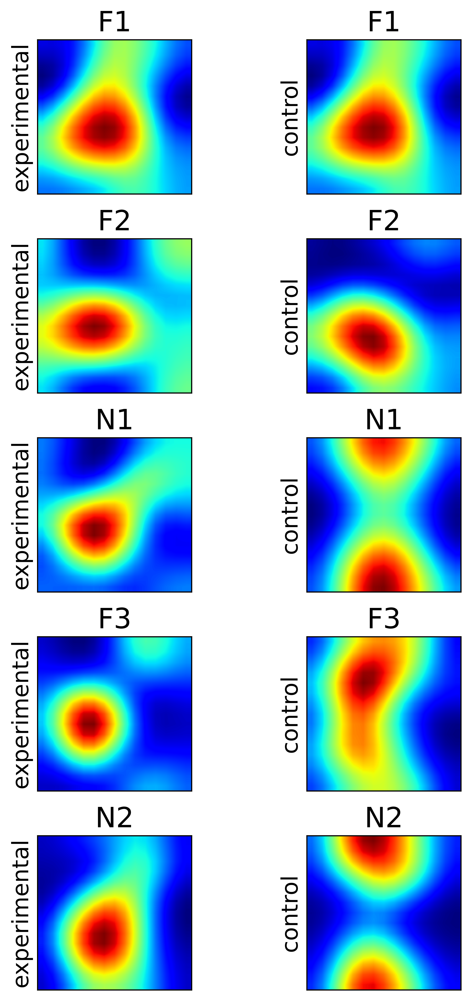

In [7]:

fig, axes = plt.subplots(5, 2, figsize=(6, 10), sharex=True, dpi=600)
for i, act_maps in enumerate([act_maps_exp, act_maps_cont]):
    axs = axes[:, i]
    
    keys_use = ['F1', 'F2', 'N1', 'F3', 'N2']

    for ax, out in zip(axs, keys_use):
        act_map = act_maps[out][120, :] # example cell
        title = out
        im = plot_one_2d_map(ax, act_map, title)
        ax.set_ylabel('experimental' if i == 0 else 'control', fontsize=16)

        # also save as standalone
        fig_single, ax_single = plt.subplots(figsize=(4, 4), dpi=600)
        ax_single.set_ylabel('experimental' if i == 0 else 'control', fontsize=16)
        im = plot_one_2d_map(ax_single, act_map, title)
        fig_single.savefig(f"plots/single_cell/{out}_{'exp' if i == 0 else 'cont'}_2dmap.svg")
        plt.close(fig_single)

plt.tight_layout()
plt.savefig('plots/single_cell_maps_multi_panel.svg')
plt.show()

In [8]:
from matplotlib.lines import Line2D

def plot_and_save(func, fname, plot_alone, *args, **kwargs):
    """Plot on given axis AND save standalone version."""
    # Plot on provided axis
    func(*args, **kwargs)

    if plot_alone:
        # Plot standalone
        fig, ax = plt.subplots(figsize=(4, 4), dpi=600)
        kwargs_single = kwargs.copy()
        kwargs_single['ax'] = ax
        func(*args, **kwargs_single)
        plt.tight_layout()
        fig.savefig(fname)
        plt.close(fig)


condition = 'exp' ## only plot experimental condition for comparison inhibitory plasticity on/off

outputs = {}
for inh_plast in [0, 1]:
    act_maps, burst_props = {}, {}
    for out in ['F1', 'F2', 'N1', 'F3', 'N2']:
        with open(f'simulation_data/2d/{condition}_{out}_inhplast_{inh_plast}.pkl', 'rb') as f:
            act_map = pickle.load(f)
        act_maps[out] = act_map

    outputs[int(str(inh_plast).split('_')[0])] = act_maps
    

fig, axes = plt.subplots(3, 4, figsize=(16, 12), dpi=600)
act_maps0, act_maps1 = smooth_act_maps([outputs[0], outputs[1]], sigma=1)

correls0, correls1 = [], []

for i, (out1, out2) in enumerate([('F1', 'F2'), ('F2', 'N1'), ('N1', 'N2')]):
    correlogram_exp = compute_cross_correlogram(act_maps0, out1, out2)
    smoothed_exp = gaussian_filter(correlogram_exp, sigma=1.5)

    correlogram_cont = compute_cross_correlogram(act_maps1, out1, out2)
    smoothed_cont = gaussian_filter(correlogram_cont, sigma=1.5)

    correls0.append(smoothed_exp)
    correls1.append(smoothed_cont)


for i, (out1, out2) in enumerate([('F1', 'F2'), ('F2', 'N1'), ('N1', 'N2')]):
    axs = axes[i, :]

    axs[0].set_ylabel('inh plast off', fontsize=20)
    axs[1].set_ylabel('inh plast F1 only', fontsize=20)

    plot_alone = False if condition == 'cont' else True


    vmin = min(np.min(correls0[i]), np.min(correls1[i]))
    vmax = max(np.max(correls0[i]), np.max(correls1[i]))

    # Cross-correlograms
    plot_and_save(plot_cross_correlogram,
                f"plots/cross_cor/{out1}_{out2}_inh0_crosscorr.svg", plot_alone,
                correls0[i], title=f'{out1} vs {out2}', ax=axs[0], ylabel='inh plast off') # , vmin=vmin, vmax=vmax)

    plot_and_save(plot_cross_correlogram,
                f"plots/cross_cor/{out1}_{out2}_inh1_crosscorr.svg", plot_alone,
                correls1[i], title=f'{out1} vs {out2}', ax=axs[1], ylabel='inh plast on') # , vmin=vmin, vmax=vmax)
    
    # Correlations
    sp0 = cor_act_maps_2d(act_maps0[out1], act_maps0[out2], which='spatial')
    sp1 = cor_act_maps_2d(act_maps1[out1], act_maps1[out2], which='spatial')

    pv0 = cor_act_maps_2d(act_maps0[out1], act_maps0[out2], which='pv')
    pv1 = cor_act_maps_2d(act_maps1[out1], act_maps1[out2], which='pv')

    cond = condition

    plot_and_save(create_raincloud_plot,
                f"plots/spatial_cor/{out1}_{out2}_raincloud_inh.svg",plot_alone,
                (sp0, sp1), out1, out2, ax=axs[2], p=None,
                colors=(COLOR_SETTINGS[f'{cond}_no_inh'],
                        COLOR_SETTINGS[f'{cond}_normal']))

    plot_and_save(plot_pv_corr_distributions,
                f"plots/pv_cor/{out1}_{out2}_pv_corr_inh.svg",plot_alone,
                (pv0, pv1), out1, out2, ax=axs[3], p=None,
                colors=(COLOR_SETTINGS[f'{cond}_no_inh'],
                        COLOR_SETTINGS[f'{cond}_normal']))
    

# Add a legend to the whole figure

legend_elements = [
    Line2D([0], [0], color=COLOR_SETTINGS[f'{cond}_no_inh'], lw=4, label='inh plast off'),
    Line2D([0], [0], color=COLOR_SETTINGS[f'{cond}_normal'], lw=4, label='inh plast on')
]

fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=16, frameon=False)

if plot_alone:
    plt.tight_layout()
    fig.savefig("plots/inh_plast_multi_panel.svg")
    plt.show()
    plt.close(fig)
    